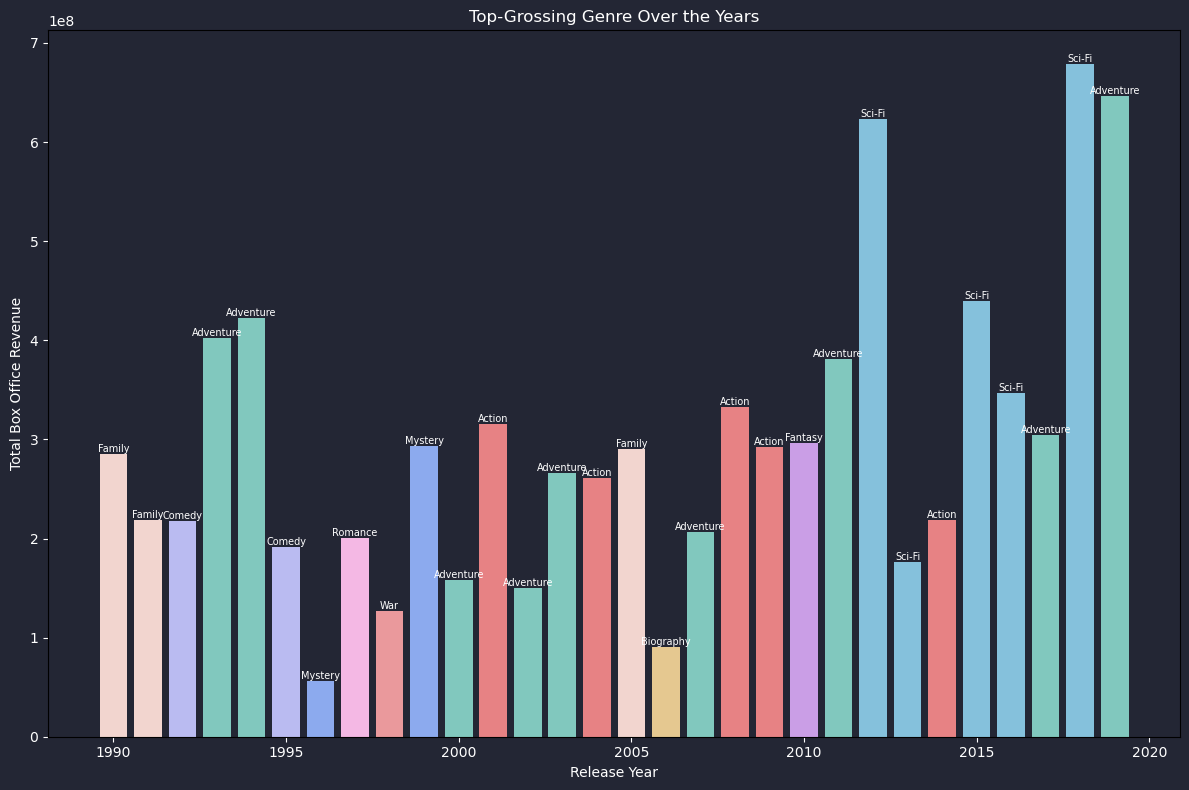

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

genre_color = { 
    "Action": "#e78284", 
    "Adventure":"#81c8be",
    "Comedy":"#babbf1",
    "Family" : "#f2d5cf",
    "Fantasy": "#ca9ee6",
    "Mystery": "#8caaee",
    "Romance": "#f4b8e4",
    "Sci-Fi": "#85c1dc",
    "War": "#ea999c",
    "Biography": "#e5c890" }  # Dictionary to decide color for each genre

data = pd.read_csv("imdb_top_1000.csv")

# DATA CLEANING

data["Gross"] = data["Gross"].str.replace(",","" ) # Replacing commas with empty strings (to convert to numbers)
data[["Gross","Released_Year"]] = data[["Gross","Released_Year"]].apply(pd.to_numeric , errors="coerce") # Converting the strings to numeric data type and non-convertible values to NaN 
data = data[data["Released_Year"]>=1990] # Considering data from 1990(3 decades)
data = data.dropna(subset=["Genre", "Gross", "Released_Year" ]) # Excluding rows with missing values
data["Genre"] = data["Genre"].str.split(",") # Splitting the genres into lists
data_30 = data.explode("Genre") # Creating a new dataframe with one row for each genre in the list for each movie
data_year_wise = (data_30 
                  .groupby(["Released_Year", "Genre"]) # Grouping according to "Released_Year" and "Genre"
                  .agg(Total_Gross=("Gross", "mean"))  # Creating the column "Total_Gross" by summing the Gross for each genre for each year  
                  .reset_index()) # Turning grouped indices back to regular columns and creating the new dataframe
top_genre = (data_year_wise
             .sort_values(["Released_Year","Total_Gross"], ascending=[True, False]) # Sorting by Released year (in ascending order) and total gross (in descending order)
             .groupby("Released_Year") # Grouping by the year
             .head(1)) # Choosing top genre (highest grossing) for each year 
top_genre["Genre"] = top_genre["Genre"].str.strip() # Stripping off the excess whitespace


# PLOTTING THE BAR GRAPH 

plt.figure(figsize=(12,8), facecolor="#232634" ) # Creating a figure(canvas) with width 12 inches and height 8 inches and adding background color 
plt.gca().set_facecolor("#232634") # Setting background color for the plotting area
top_genre["Color"] = top_genre["Genre"].map(genre_color).fillna("#babbf1") # Creating a column with colors according to genre 
plt.rcParams.update({
    "text.color": "white", # Setting all text color to white 
    "axes.labelcolor": "white", # Setting the axes label ( x and y axes) color to white 
    "axes.titlecolor": "white", # Setting the color of title to white 
    "xtick.color": "white", # Setting the tick labels of x-axis to white
    "ytick.color": "white" # Setting the tick labels of y-axis to white
})

plt.bar( 
    top_genre["Released_Year"], # Setting x-axis data as Released_Year
    top_genre["Total_Gross"], # Setting y-axis data as Total_Gross
    color=top_genre["Color"]) # Setting color of each bar 
for _, row in top_genre.iterrows():
    plt.text(
        row["Released_Year"], # X-coordinate of the text (on the x-axis)
        row["Total_Gross"], # Y-coordinate of the text (on the y-axis)
        row["Genre"], # The actual text to display
        ha='center', # Horizontal Alignment
        va='bottom', # Vertical Alignment
        fontsize=7) # Text size
    
plt.xlabel("Release Year") # Label for x-axis
plt.ylabel("Total Box Office Revenue") # Label for y-axis
plt.title("TOP-GROSSING GENRE OVER THE YEARS") # Title of the plot
plt.tight_layout() # Adjusting layout to prevent overlap of labels and titles
plt.show()